In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Con $\tau = \lVert R\,t \rVert_\infty$, la sensibilidad de la duración del proyecto a cada actividad es el gradiente $\partial\tau/\partial t_i$. Considere el proyecto cuyo cuadro se adjunta, que tiene más de una ruta crítica.

In [3]:
pregunta_1 = "1. Construya R, calcule R·t y determine las rutas críticas.  "
pregunta_2 = "2. Calcule ∂τ/∂t_i para cada actividad como la media de los vectores indicadores de las rutas críticas (lo que da `tau_sensitivity`). ¿Qué valores aparecen y qué significan 1, 0 y los intermedios?  "
pregunta_3 = "3. Compruebe por diferencias finitas, para una actividad de cada clase, qué ocurre con τ al aumentar y al disminuir su duración en un día. ¿Por qué la derivada «no existe» en las actividades intermedias?  "
pregunta_4 = "4. Demuestre que la suma de las sensibilidades es la longitud (en número de actividades) media de las rutas críticas y compruébelo.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Construya R, calcule R·t y determine las rutas críticas.  

2. Calcule ∂τ/∂t_i para cada actividad como la media de los vectores indicadores de las rutas críticas (lo que da `tau_sensitivity`). ¿Qué valores aparecen y qué significan 1, 0 y los intermedios?  

3. Compruebe por diferencias finitas, para una actividad de cada clase, qué ocurre con τ al aumentar y al disminuir su duración en un día. ¿Por qué la derivada «no existe» en las actividades intermedias?  

4. Demuestre que la suma de las sensibilidades es la longitud (en número de actividades) media de las rutas críticas y compruébelo.  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 6       ),
    ('B'     , '---'      , 6       ),
    ('C'     , '---'      , 2       ),
    ('D'     , 'A,B,C'    , 1       ),
    ('E'     , 'D'        , 1       ),
    ('F'     , 'D'        , 5       ),
    ('G'     , 'F'        , 1       ),
    ('H'     , 'E,G'      , 6       ),
    ('I'     , 'H'        , 7       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,6
B,---,6
C,---,2
D,"A,B,C",1
E,D,1
F,D,5
G,F,1
H,"E,G",6
I,H,7


# Resolución

In [5]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
R = proyecto.path_matrix(dummies=False)
t = datos_proyecto['duration'][R.columns]

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. Construya R, calcule R·t y determine las rutas críticas.  

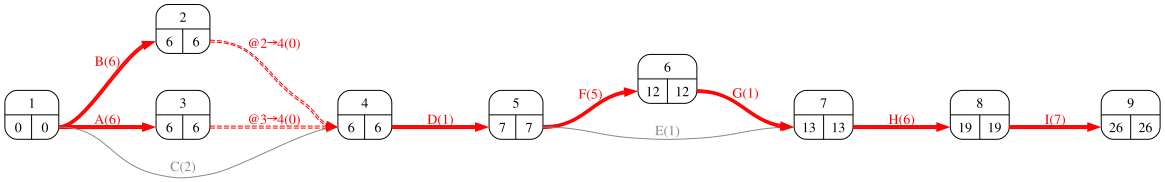

In [7]:
#| fig-cap: "Grafo PERT con tiempos y rutas críticas"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [8]:
Rt = R @ t
tau = float(Rt.max())
criticas = Rt.index[np.isclose(Rt, tau)].tolist()
display(pd.DataFrame({'actividades': [' - '.join(R.columns[R.loc[r] == 1]) for r in R.index], 'duración': Rt}))
Markdown(f'τ = {tau:.0f}; rutas críticas: {", ".join(criticas)}.')

,actividades,duración
Route_1,A - D - E - H - I,21
Route_2,A - D - F - G - H - I,26
Route_3,B - D - E - H - I,21
Route_4,B - D - F - G - H - I,26
Route_5,C - D - E - H - I,17
Route_6,C - D - F - G - H - I,22


τ = 26; rutas críticas: Route_2, Route_4.

## Apartado 2

In [9]:
display(Markdown(pregunta_2))

2. Calcule ∂τ/∂t_i para cada actividad como la media de los vectores indicadores de las rutas críticas (lo que da `tau_sensitivity`). ¿Qué valores aparecen y qué significan 1, 0 y los intermedios?  

In [10]:
indicadores = R.loc[criticas]
gradiente = indicadores.mean()
display(indicadores)
pd.DataFrame({'∂τ/∂t (media de indicadores)': gradiente, 'tau_sensitivity': proyecto.tau_sensitivity(t.to_dict()).reindex(R.columns)}).T

,A,B,C,D,E,F,G,H,I
Route_2,1,0,0,1,0,1,1,1,1
Route_4,0,1,0,1,0,1,1,1,1


,A,B,C,D,E,F,G,H,I
∂τ/∂t (media de indicadores),0.5,0.5,0.0,1.0,0.0,1.0,1.0,1.0,1.0
tau_sensitivity,0.5,0.5,0.0,1.0,0.0,1.0,1.0,1.0,1.0


Valor 1: la actividad está en todas las rutas críticas (alargarla o acortarla cambia τ uno a uno). Valor 0: no está en ninguna (τ no cambia, al menos para cambios pequeños). Valor intermedio, por ejemplo 0,5: está en una de las dos rutas críticas; alargarla sí alarga el proyecto, pero acortarla no lo acorta, porque la otra ruta sigue midiendo lo mismo.

## Apartado 3

In [11]:
display(Markdown(pregunta_3))

3. Compruebe por diferencias finitas, para una actividad de cada clase, qué ocurre con τ al aumentar y al disminuir su duración en un día. ¿Por qué la derivada «no existe» en las actividades intermedias?  

In [12]:
def tau_con(act, delta):
    t2 = t.copy(); t2[act] += delta
    return float((R @ t2).max())
clases = {v: gradiente.index[np.isclose(gradiente, v)].tolist() for v in sorted(gradiente.unique())}
filas = {}
for v, acts in clases.items():
    a = acts[0]
    filas[a] = {'∂τ/∂t': v, 'τ(t+1) − τ': tau_con(a, 1) - tau, 'τ(t−1) − τ': tau_con(a, -1) - tau}
pd.DataFrame(filas).T

,∂τ/∂t,τ(t+1) − τ,τ(t−1) − τ
C,0.0,0.0,0.0
A,0.5,1.0,0.0
D,1.0,1.0,-1.0


Para las actividades con valor intermedio la pendiente por la derecha (+1) y por la izquierda (0) son distintas: τ es un máximo de funciones lineales y en los puntos donde dos rutas empatan tiene una esquina. La media de los indicadores es un *subgradiente*, no una derivada: el valor que reparte la sensibilidad entre las rutas empatadas.

## Apartado 4

In [13]:
display(Markdown(pregunta_4))

4. Demuestre que la suma de las sensibilidades es la longitud (en número de actividades) media de las rutas críticas y compruébelo.  

In [14]:
suma = float(gradiente.sum())
longitud_media = float(indicadores.sum(axis=1).mean())
Markdown(f'''Σ_i ∂τ/∂t_i = Σ_i (1/k) Σ_{{r crítica}} R_ri = (1/k) Σ_r Σ_i R_ri = media del número de actividades de las rutas críticas. Aquí Σ = {suma:.2f} y la longitud media de las {len(criticas)} rutas críticas es {longitud_media:.2f}.''')

Σ_i ∂τ/∂t_i = Σ_i (1/k) Σ_{r crítica} R_ri = (1/k) Σ_r Σ_i R_ri = media del número de actividades de las rutas críticas. Aquí Σ = 6.00 y la longitud media de las 2 rutas críticas es 6.00.